## Synthetic laboratory data

This notebook uses NumPy to generate a synthetic dataset of 200 samples with four laboratory measurements: hemoglobin, glucose, creatinine, and CRP.

A fixed random seed of 42 is used to make the results reproducible.

| Hemoglobin | g/L |  
| Glucose | mg/dL |  
| Creatinine | mg/dL |  
| CRP | mg/L |  

The measurements are generated from normal distributions using synthetic means and standard deviations. These values are illustrative and do not reflect real-life values.

In [61]:
import numpy as np
import timeit
import matplotlib.pyplot as plt

In [62]:
rng = np.random.default_rng(seed=42)

In [63]:
hemoglobin = rng.normal(
    loc = 145,
    scale=12.5,
    size=200
)
glucose = rng.normal(
    loc = 85,
    scale=7.5,
    size=200
)
creatinine = rng.normal(
    loc = 0.9,
    scale=0.2,
    size=200
)
crp = rng.normal(
    loc = 0.8,
    scale=0.2,
    size=200
)

In [64]:
data = np.stack((hemoglobin, glucose, creatinine, crp), axis=-1)
column_names = ["hemoglobin", "glucose", "creatinine", "CRP"]
units = ["g/L", "mg/dL", "mg/dL", "mg/L"]

In [65]:
print(data.shape)
print(data.dtype)
print(data[:5])

(200, 4)
float64
[[148.8089635   87.53180912   0.86407772   0.90308208]
 [132.00019867  95.55611396   0.93935522   0.68449222]
 [154.38063995  85.6793868    1.0641057    1.05488944]
 [156.75705895  89.82954095   0.82125177   0.67448249]
 [120.61206014  69.62370924   1.00423345   0.67267694]]


In [66]:
upper_limits = np.array([190, 105, 1.3, 1.1])
lower_limits = np.array([100, 75, 0.45, 0.2])

In [67]:
means = data.mean(axis=0)
stds = data.std(axis=0)

In [68]:
print(means, means.shape)
print(stds, stds.shape)

[144.61936594  85.15058211   0.8863754    0.79265319] (4,)
[10.99656679  7.62714688  0.20279245  0.20302242] (4,)


In [69]:
def standardize_with_vector(data, means, stds):
    return (data - means) / stds

In [70]:
standardized = standardize_with_vector(data, means, stds)

In [71]:
standardized.shape

(200, 4)

In [72]:
standardized[:5]

array([[ 0.38099142,  0.31220416, -0.10995322,  0.54392463],
       [-1.14755519,  1.36427579,  0.26125145, -0.5327538 ],
       [ 0.8876656 ,  0.06933191,  0.87641478,  1.29166157],
       [ 1.10377114,  0.61346122, -0.32113442, -0.58205736],
       [-2.18316373, -2.03573802,  0.58117575, -0.59095071]])

In [73]:
print(standardized.mean(axis=0))
print(standardized.std(axis=0))

[ 3.88994392e-16 -1.49658064e-15 -2.85771407e-15  2.87943280e-15]
[1. 1. 1. 1.]


In [74]:
below_range = data < lower_limits
above_range = data > upper_limits

In [75]:
print(below_range.shape)
print(above_range.shape)

(200, 4)
(200, 4)


In [76]:
abnormal = below_range | above_range
abnormal_counts = abnormal.sum(axis=1)

In [77]:
print(abnormal_counts)

[0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 1 0 0 0 0 1
 0 0 0 0 0 2 1 0 0 0 0 1 0 1 0 1 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 1 0 0 1 0 1 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 1 1 0
 1 0 0 0 0 2 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 1 0 0 1 0 2 0 1
 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0]


In [78]:
def standardize_with_loop(data, means, stds):
    standardized_loop = []
    for row in data:
        new_row =[]
        for i, col in enumerate(row):
            new_row.append((col - means[i]) / stds[i])
        standardized_loop.append(new_row)
    return np.array(standardized_loop)

In [79]:
standardized_loop = standardize_with_loop(data, means, stds)

In [80]:
print(standardized_loop[:5])

[[ 0.38099142  0.31220416 -0.10995322  0.54392463]
 [-1.14755519  1.36427579  0.26125145 -0.5327538 ]
 [ 0.8876656   0.06933191  0.87641478  1.29166157]
 [ 1.10377114  0.61346122 -0.32113442 -0.58205736]
 [-2.18316373 -2.03573802  0.58117575 -0.59095071]]


In [81]:
print(standardized[:5])

[[ 0.38099142  0.31220416 -0.10995322  0.54392463]
 [-1.14755519  1.36427579  0.26125145 -0.5327538 ]
 [ 0.8876656   0.06933191  0.87641478  1.29166157]
 [ 1.10377114  0.61346122 -0.32113442 -0.58205736]
 [-2.18316373 -2.03573802  0.58117575 -0.59095071]]


In [82]:
print((standardized == standardized_loop).sum())

800


# Measuring execution time

The execution time for standardizing the dataset was compared using two different appproaches: a vectorized approach and a loop-based approach. The execution times were measured using 'timeit', with each operation run 1,000 times. The loop-based approach took 0.2827 seconds, while the vectorized approach took 0.0035 seconds. This means the vectorized approach was approximately 63 times faster in this test. 

In [83]:
timeit.timeit(
    lambda: standardize_with_loop(data, means, stds),
    number=1000
)

0.2723659999996926

In [84]:
timeit.timeit(
    lambda: standardize_with_vector(data, means, stds),
    number=1000
)

0.0038427999998020823

# Plotting

In [85]:
print(column_names, units)

['hemoglobin', 'glucose', 'creatinine', 'CRP'] ['g/L', 'mg/dL', 'mg/dL', 'mg/L']


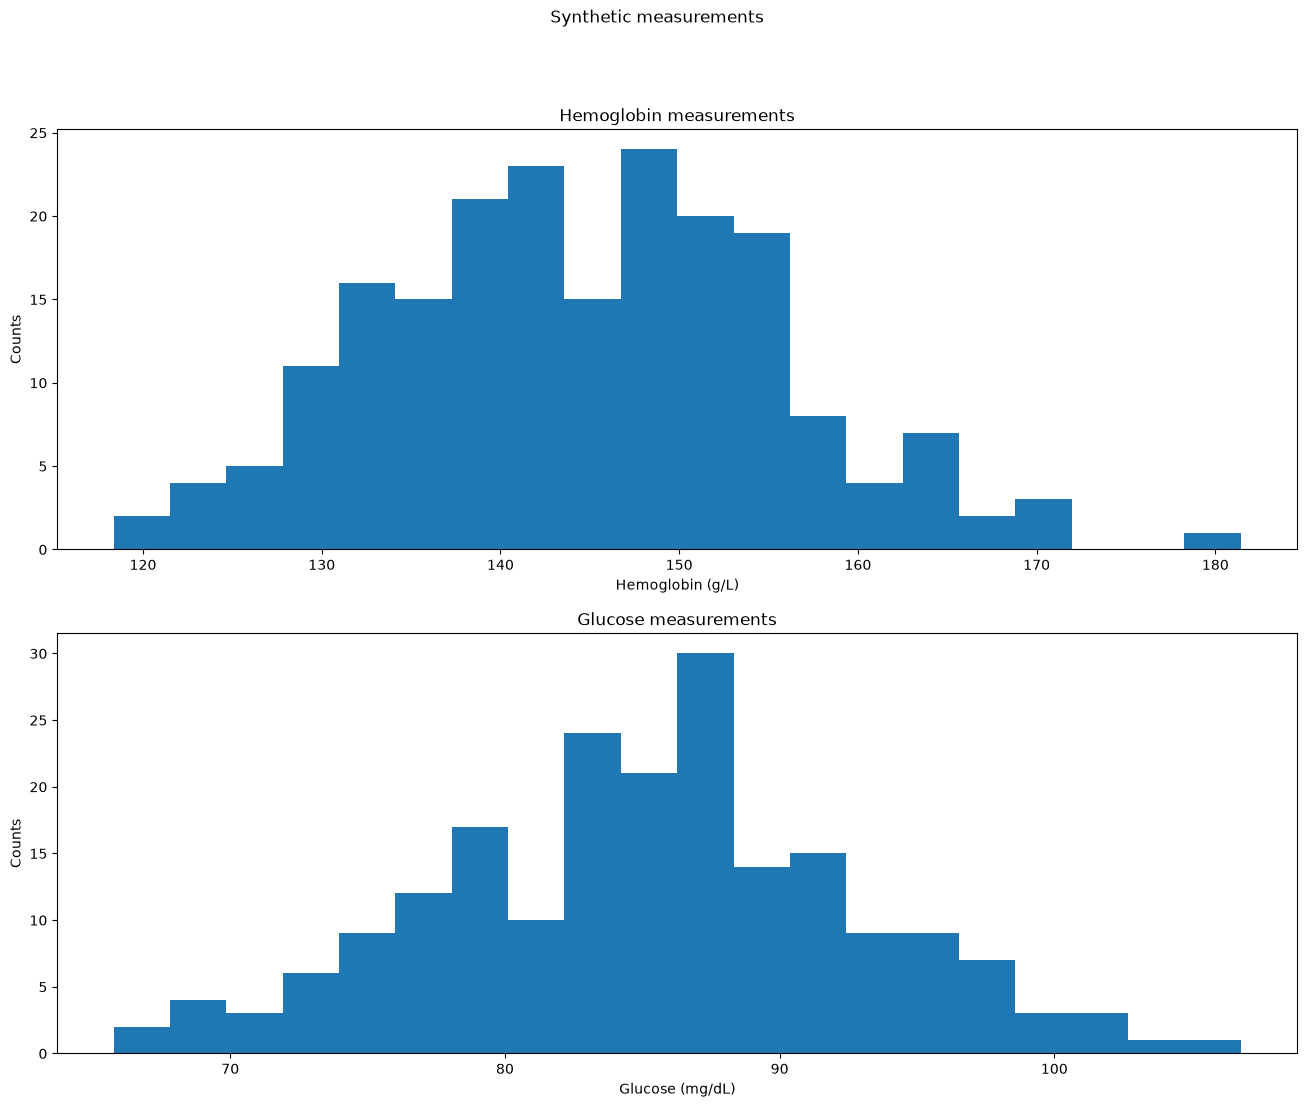

In [91]:
fig, axs = plt.subplots(2,1, figsize=(16,12))

fig.suptitle("Synthetic measurements")

axs[0].hist(x=data[:,0], bins=20)
axs[0].set_title(f"{column_names[0].capitalize()} measurements")
axs[0].set_xlabel(f"{column_names[0].capitalize()} ({units[0]})")
axs[0].set_ylabel("Counts")

axs[1].hist(x=data[:,1], bins=20)
axs[1].set_title(f"{column_names[1].capitalize()} measurements")
axs[1].set_xlabel(f"{column_names[1].capitalize()} ({units[1]})")
axs[1].set_ylabel("Counts")

plt.show()


# Testing

In [93]:
test_data = np.array([10, 20, 30])      # mean = 20, std = 8.165
test_data_calc_standardized = np.array([-1.225, 0, 1.225])

test_data_func_standardized = standardize_with_vector(test_data, test_data.mean(), test_data.std())
print(test_data_func_standardized)

[-1.22474487  0.          1.22474487]


In [98]:
np.testing.assert_allclose(
    test_data_func_standardized,
    test_data_calc_standardized,
    atol=0.001
)

In [100]:
np.testing.assert_allclose(
    standardized,
    standardized_loop,
    atol=0.0001
)